# Power Plant Energy Prediction

Predict power plant energy output (PE) from temperature (AT), exhaust vacuum (V), pressure (AP), and humidity (RH).

See [README.md](README.md) for data, setup, workflow, and evaluation notes.

In [1]:
import random
import numpy as np
import torch
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(4)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


In [2]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split

In [3]:
df = pd.read_csv("power_plant.csv")

In [4]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [5]:
#AT => Temperature
#V => Vaccum
#AP => Pressure
#RH => Humidity

#PE => Produced Energy

In [6]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [7]:
X = df.drop("PE",axis=1)
y = df["PE"]

In [8]:
y.head()

0    480.48
1    445.75
2    438.76
3    453.09
4    464.43
Name: PE, dtype: float64

In [9]:
#Split out data

X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.2,random_state=42
)

# Keep the test set untouched during checkpoint selection.
X_train,X_val,y_train,y_val = train_test_split(
    X_train,y_train,test_size=0.2,random_state=42
)
print(f"Train: {len(X_train)}, validation: {len(X_val)}, test: {len(X_test)}")


Train: 6123, validation: 1531, test: 1914


In [10]:
df.shape

(9568, 5)

In [11]:
#Scaling Data 

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_val_scaled = scaler.transform(X_val)


In [12]:
X_test_scaled

array([[ 1.34189472,  0.22370754, -1.28311894, -1.10740679],
       [ 0.80516658,  1.3452179 , -0.73681857,  0.2652126 ],
       [-0.25483787, -0.75182597,  2.00995251, -0.19759945],
       ...,
       [-0.68395135, -1.17092081, -0.29400989, -0.10682502],
       [ 1.31095551,  1.32010361, -0.8691522 , -0.4437907 ],
       [-0.27232526, -0.28407217,  0.38123093,  1.10831449]],
      shape=(1914, 4))

In [13]:
X_train_tensor = torch.tensor(X_train_scaled,dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled,dtype=torch.float32)

y_train_tensor = torch.tensor(y_train.values,dtype=torch.float32).view(-1,1)
y_test_tensor = torch.tensor(y_test.values,dtype=torch.float32).view(-1,1)
X_val_tensor = torch.tensor(X_val_scaled,dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.values,dtype=torch.float32).view(-1,1)


In [14]:
type(X_train_scaled)

numpy.ndarray

In [15]:
type(y_train)

pandas.Series

In [16]:
y_train.shape

(6123,)

In [17]:
from torch.utils.data import TensorDataset,DataLoader

train_dataset = TensorDataset(X_train_tensor,y_train_tensor)
test_dataset = TensorDataset(X_test_tensor,y_test_tensor)
val_dataset = TensorDataset(X_val_tensor,y_val_tensor)


In [18]:
train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True)
test_loader = DataLoader(test_dataset,batch_size=32)
val_loader = DataLoader(val_dataset,batch_size=32)


## Deep Learning

In [19]:
# Build our ANN Model

class ANN(nn.Module):
    def __init__(self):
        super(ANN,self).__init__()
        
        self.model = nn.Sequential(
        #1st Hidden Layer
        nn.Linear(X_train.shape[1],6),
        nn.ReLU(),

        #2nd Hidden Layer
        nn.Linear(6,6),
        nn.ReLU(),

        #Output Layer
        nn.Linear(6,1)
        )
   

    def forward(self,x):
        return self.model(x)

In [20]:
import torch.optim as optim

model = ANN()

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters())

In [21]:
#Train the ANN
train_losses = []
val_losses = []

best_val_loss = float("inf") 

epochs = 100

for epoch in range(epochs):
    model.train()
    running_loss = 0.0 # total training loss for 1 epoch
    
    for xb,yb in train_loader:
        #xb = features of 1 batch
        #yb = labels of 1 batch
        optimizer.zero_grad()
        
        outputs = model(xb) #forward prop ... predicted outputs for this batch
        loss = criterion(outputs,yb) #compute loss
        loss.backward() #back prop .... compute gradients
        optimizer.step() #params update

        running_loss += loss.item() * xb.size(0) # loss is tensor => python float value

    epoch_train_loss = running_loss/len(train_dataset)
    train_losses.append(epoch_train_loss)

    #Validation
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for xb,yb in val_loader:
            outputs = model(xb)
            loss = criterion(outputs,yb)
            running_val_loss += loss.item() * xb.size(0)

    epoch_val_loss = running_val_loss/len(val_dataset)
    val_losses.append(epoch_val_loss)

    print(
    f"Epoch {epoch+1}/{epochs} ==> "
    f"Training Loss = {epoch_train_loss:.4f} | "
    f"Validation Loss = {epoch_val_loss:.4f}"
)       

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(),"best_model.pt") #pt or pth file

Epoch 1/100 ==> Training Loss = 205902.0996 | Validation Loss = 206036.5216
Epoch 2/100 ==> Training Loss = 202731.7238 | Validation Loss = 199988.1988


Epoch 3/100 ==> Training Loss = 192285.0412 | Validation Loss = 184283.6421
Epoch 4/100 ==> Training Loss = 171280.4966 | Validation Loss = 157693.9013


Epoch 5/100 ==> Training Loss = 140621.3817 | Validation Loss = 123280.6657
Epoch 6/100 ==> Training Loss = 105311.6148 | Validation Loss = 87816.9676


Epoch 7/100 ==> Training Loss = 72727.3573 | Validation Loss = 58801.3586
Epoch 8/100 ==> Training Loss = 48677.5769 | Validation Loss = 39867.9082


Epoch 9/100 ==> Training Loss = 34244.9460 | Validation Loss = 29562.3328
Epoch 10/100 ==> Training Loss = 26536.5557 | Validation Loss = 24211.0646


Epoch 11/100 ==> Training Loss = 22273.9457 | Validation Loss = 21039.1067
Epoch 12/100 ==> Training Loss = 19483.8757 | Validation Loss = 18683.4414


... (40 outputs left out)

Epoch 93/100 ==> Training Loss = 20.9355 | Validation Loss = 22.0746
Epoch 94/100 ==> Training Loss = 21.0699 | Validation Loss = 22.1452


Epoch 95/100 ==> Training Loss = 21.0145 | Validation Loss = 21.9980
Epoch 96/100 ==> Training Loss = 21.0312 | Validation Loss = 21.7061


Epoch 97/100 ==> Training Loss = 21.0374 | Validation Loss = 22.5640
Epoch 98/100 ==> Training Loss = 20.9086 | Validation Loss = 22.6514


Epoch 99/100 ==> Training Loss = 21.0180 | Validation Loss = 21.6404
Epoch 100/100 ==> Training Loss = 21.0034 | Validation Loss = 21.9577


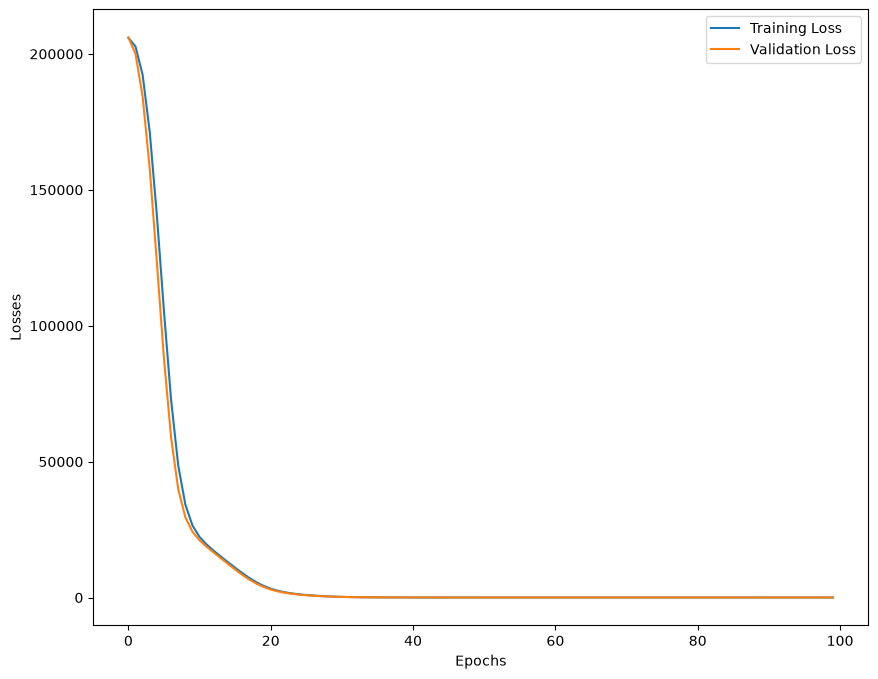

In [22]:
import matplotlib.pyplot as plt

loss_df = pd.DataFrame({
    "Training Loss" : train_losses,
    "Validation Loss" : val_losses
})

plt.figure(figsize=(10,8))
plt.plot(loss_df["Training Loss"],label="Training Loss")
plt.plot(loss_df["Validation Loss"],label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()

In [23]:
#Loading the best model

model.load_state_dict(torch.load("best_model.pt",weights_only=True))

<All keys matched successfully>

In [24]:
#Evaluate our Model

model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse_loss = criterion(train_preds,y_train_tensor)
    test_mse_loss = criterion(test_preds,y_test_tensor)
    
print("Training MSE : ",train_mse_loss.item())
print("Testing MSE : ",test_mse_loss.item())

Training MSE :  20.69744110107422
Testing MSE :  19.23892593383789


In [25]:
from sklearn.metrics import r2_score

print("R2 Score : ",r2_score(y_test,test_preds.numpy()))

R2 Score :  0.9327649247533074


In [26]:
predicted_df = pd.DataFrame(test_preds.numpy(),columns=["Predicted Values"])
actual_df = pd.DataFrame(y_test.values,columns=["Actual Values"])

pd.concat([predicted_df,actual_df],axis=1)

,Predicted Values,Actual Values
0,435.726227,433.27
1,437.031738,438.16
2,461.407684,458.42
3,476.207489,480.82
4,435.574188,441.41
...,...,...
1909,451.571686,456.70
1910,431.909454,438.04
1911,467.923767,467.80
1912,431.280609,437.14


## Final test metrics and prediction diagnostics
The held-out test set is evaluated after selecting the checkpoint on a separate validation set.

MAE     3.505037
RMSE    4.386220
R2      0.932765
Name: Held-out test metrics, dtype: float64


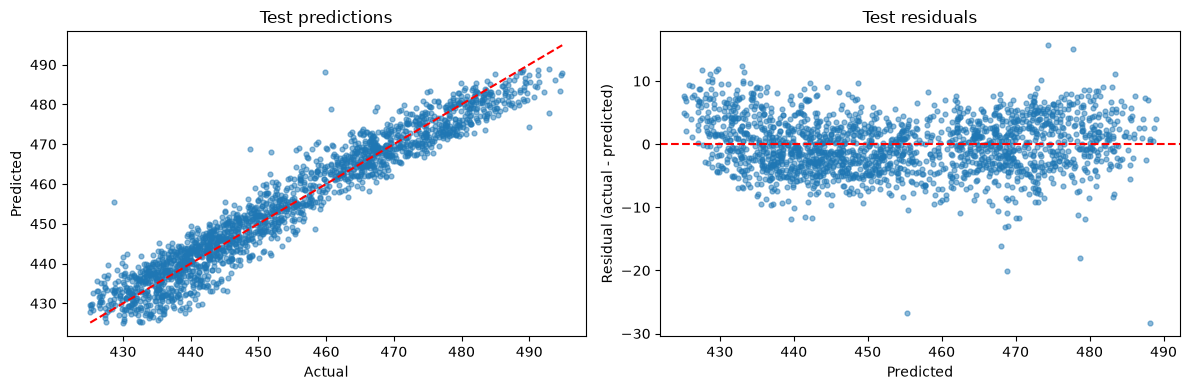

,Actual,Predicted
0,433.27,435.726227
1,438.16,437.031738
2,458.42,461.407684
3,480.82,476.207489
4,441.41,435.574188
5,454.75,459.341553
6,483.26,481.288483
7,478.25,478.968842
8,434.16,439.249481
9,470.66,469.976105


In [27]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

actual = y_test.to_numpy()
predictions = test_preds.numpy().ravel()
results = {
    "MAE": mean_absolute_error(actual, predictions),
    "RMSE": float(np.sqrt(mean_squared_error(actual, predictions))),
    "R2": r2_score(actual, predictions),
}
print(pd.Series(results, name="Held-out test metrics"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(actual, predictions, alpha=0.5, s=12)
limits = [min(actual.min(), predictions.min()), max(actual.max(), predictions.max())]
axes[0].plot(limits, limits, "r--")
axes[0].set(xlabel="Actual", ylabel="Predicted", title="Test predictions")
axes[1].scatter(predictions, actual - predictions, alpha=0.5, s=12)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set(xlabel="Predicted", ylabel="Residual (actual - predicted)", title="Test residuals")
plt.tight_layout()
plt.show()
pd.DataFrame({"Actual": actual, "Predicted": predictions}).head(10)
